In [1]:
!pip install matplotlib sklearn tensorly imagecodecs

  Using cached sklearn-0.0.post12.tar.gz (2.6 kB)
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'error'


  error: subprocess-exited-with-error
  
  python setup.py egg_info did not run successfully.
  exit code: 1
  
  [15 lines of output]
  The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
  rather than 'sklearn' for pip commands.
  
  Here is how to fix this error in the main use cases:
  - use 'pip install scikit-learn' rather than 'pip install sklearn'
  - replace 'sklearn' by 'scikit-learn' in your pip requirements files
    (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
  - if the 'sklearn' package is used by one of your dependencies,
    it would be great if you take some time to track which package uses
    'sklearn' instead of 'scikit-learn' and report it to their issue tracker
  - as a last resort, set the environment variable
    SKLEARN_ALLOW_DEPRECATED_SKLEARN_PACKAGE_INSTALL=True to avoid this error
  
  More information is available at
  https://github.com/scikit-learn/sklearn-pypi-package
  [end of output]
  
  note: This error originates from a subpr

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, exposure
from sklearn.preprocessing import MinMaxScaler
import tensorly as tl
from tensorly.decomposition import parafac
from tensorly.cp_tensor import cp_to_tensor
import imagecodecs

C:\Users\HP\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been deprecated
  "class": algorithms.Blowfish,


In [3]:
# Set the main directory where your images are located
main_dir = r"C:\Users\HP\Desktop\Flood_dataset"

# List all .tif files in the directoryimport os
from skimage import io
import imagecodecs  # Ensure LZW support for .tif files

# Set the main directory where your images are located
main_dir = r"C:\Users\HP\Desktop\Flood_dataset"

# Check if the directory exists
if not os.path.exists(main_dir):
    print(f"Error: Directory '{main_dir}' not found!")
    exit()

# List all .tif files in the directory
image_files = [f for f in os.listdir(main_dir) if f.lower().endswith('.tif')]

if not image_files:
    print("No .tif images found in the directory!")
else:
    print(f"Found {len(image_files)} .tif images.")

# Load images into a dictionary
images = {}

for img_file in image_files:
    img_path = os.path.join(main_dir, img_file)
    try:
        image = io.imread(img_path)  # Load image
        if image is None or image.size == 0:
            print(f"Warning: {img_file} is empty or not readable!")
        else:
            images[img_file] = image
    except Exception as e:
        print(f"Error loading {img_file}: {e}")

print(f"Successfully loaded {len(images)} images.")

image_files = [f for f in os.listdir(main_dir) if f.endswith('.tif')]
if not image_files:
    print("No .tif images found in the directory!")

# Load images into a dictionary
images = {}
for img_file in image_files:
    img_path = os.path.join(main_dir, img_file)
    try:
        images[img_file] = io.imread(img_path)
    except Exception as e:
        print(f"Error loading {img_file}: {e}")

Found 28 .tif images.
Successfully loaded 28 images.


In [4]:
# Function: Spectral Band Normalization
def normalize_image(image):
    scaler = MinMaxScaler()
    norm_image = np.zeros_like(image, dtype=np.float32)
    for i in range(image.shape[-1]):  # Normalize each spectral band
        norm_image[..., i] = scaler.fit_transform(image[..., i].reshape(-1, 1)).reshape(image[..., i].shape)
    return norm_image

# Function: Outlier Removal
def remove_outliers(image, threshold=2):
    mean = np.mean(image, axis=(0, 1))
    std = np.std(image, axis=(0, 1))
    return np.clip(image, mean - threshold * std, mean + threshold * std)

# Apply Preprocessing
processed_images = {}
for name, img in images.items():
    norm_img = normalize_image(img)
    processed_images[name] = remove_outliers(norm_img)




In [5]:
# Visualize Processed Images
if processed_images:
    fig, axes = plt.subplots(len(processed_images), 1, figsize=(10, len(processed_images) * 5))
    if len(processed_images) == 1:
        axes = [axes]
    for ax, (name, img) in zip(axes, processed_images.items()):
        ax.imshow(img[..., 0], cmap='gray')  # Display first spectral band
        ax.set_title(f"Processed {name}")
        ax.axis('off')
    plt.show()

In [6]:
# Function: HOOI Compression (Tensor Decomposition)
def hooi_compression(image, rank=50):
    """
    Apply CP Decomposition for tensor compression.

    Args:
        image (numpy array): Input image tensor.
        rank (int): Rank for decomposition.

    Returns:
        core (numpy array): Compressed tensor.
    """
    image_tensor = tl.tensor(image)  # Convert to tensorly tensor
    rank = min(image_tensor.shape) if isinstance(rank, tuple) else rank  # Ensure valid rank
    try:
        factors = parafac(image_tensor, rank=rank, init='random')
        core = cp_to_tensor(factors)
        return core
    except Exception as e:
        print(f"Compression failed for an image: {e}")
        return None

# Apply HOOI Compression
compressed_images = {}
for name, img in processed_images.items():
    compressed_img = hooi_compression(img)
    if compressed_img is not None:
        compressed_images[name] = compressed_img

C:\Users\HP\anaconda3\Lib\site-packages\tensorly\backend\__init__.py:202: RuntimeWarning: invalid value encountered in sqrt
  return getattr(
C:\Users\HP\anaconda3\Lib\site-packages\tensorly\decomposition\_cp.py:414: RuntimeWarning: overflow encountered in multiply
  pseudo_inverse = pseudo_inverse * tl.dot(
C:\Users\HP\anaconda3\Lib\site-packages\tensorly\decomposition\_cp.py:414: RuntimeWarning: invalid value encountered in multiply
  pseudo_inverse = pseudo_inverse * tl.dot(


Compression failed for an image: Singular matrix





In [7]:
# Visualize Compressed Images
if compressed_images:
    fig, axes = plt.subplots(len(compressed_images), 1, figsize=(10, len(compressed_images) * 5))
    if len(compressed_images) == 1:
        axes = [axes]
    for ax, (name, img) in zip(axes, compressed_images.items()):
        ax.imshow(img[..., 0], cmap='gray')  # Display first spectral band of compressed image
        ax.set_title(f"Compressed {name} using HOOI")
        ax.axis('off')
    plt.show()

In [8]:
# Function: CLAHE Image Enhancement
def apply_clahe(image):
    """
    Apply CLAHE (Contrast Limited Adaptive Histogram Equalization) to the first spectral band.

    Args:
        image (numpy array): Input compressed image.

    Returns:
        enhanced_image (numpy array): Image after applying CLAHE.
    """
    band = image[..., 0]  # Select first spectral band
    band = (band * 255).astype(np.uint8)  # Convert to 8-bit format for CLAHE
    clahe = exposure.equalize_adapthist(band, clip_limit=0.03)  # CLAHE enhancement
    return clahe

# Apply CLAHE to Compressed Images
enhanced_images = {}
for name, img in compressed_images.items():
    enhanced_images[name] = apply_clahe(img)

C:\Users\HP\AppData\Local\Temp\ipykernel_12460\2633433399.py:13: RuntimeWarning: invalid value encountered in cast
  band = (band * 255).astype(np.uint8)  # Convert to 8-bit format for CLAHE





In [9]:
# Visualize Enhanced Images
if enhanced_images:
    fig, axes = plt.subplots(len(enhanced_images), 1, figsize=(10, len(enhanced_images) * 5))
    if len(enhanced_images) == 1:
        axes = [axes]
    for ax, (name, img) in zip(axes, enhanced_images.items()):
        ax.imshow(img, cmap='gray')  # Display CLAHE-enhanced image
        ax.set_title(f"CLAHE Enhanced {name}")
        ax.axis('off')
    plt.show()

In [10]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from sklearn.model_selection import train_test_split
import numpy as np

# Hyperparameters
patch_size = 32
batch_size = 32
learning_rate = 0.001
num_epochs = 20
num_classes = 2

X = []
y = []

# Process each image in the dataset
for name, img in enhanced_images.items():
    label = 0 if 'no_flood' in name else 1
    
    # Ensure the image has a depth dimension (if 2D, add a fake depth)
    if img.ndim == 2:  # Grayscale image case (H, W)
        img = np.expand_dims(img, axis=0)  # Convert to (1, H, W)

    depth, height, width = img.shape  # Now shape is (D, H, W)
    
    # Set an appropriate depth value
    adjusted_depth = min(depth, 8)  

    # Extract patches, ensuring proper depth
    for d in range(0, max(1, depth - adjusted_depth + 1), adjusted_depth):  
        for i in range(0, max(1, height - patch_size + 1), patch_size):
            for j in range(0, max(1, width - patch_size + 1), patch_size):
                patch = img[d:d+adjusted_depth, i:i+patch_size, j:j+patch_size]
                
                # Ensure patch has the correct shape
                if patch.shape == (adjusted_depth, patch_size, patch_size):
                    X.append(patch)
                    y.append(label)

# Convert to NumPy arrays
X = np.array(X)
y = np.array(y)

# Ensure correct shape for 3D CNN input (Batch, Channels, Depth, Height, Width)
X = X.reshape(-1, 1, adjusted_depth, patch_size, patch_size)

# Train-Test Split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.3, random_state=42)

# Custom Dataset Class
class HyperspectralDataset(Dataset):
    def __init__(self, images, labels):
        self.images = torch.tensor(images, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.long)
        
    def __len__(self):
        return len(self.labels)
    
    def __getitem__(self, idx):
        return self.images[idx], self.labels[idx]

# Create Data Loaders
train_dataset = HyperspectralDataset(X_train, y_train)
val_dataset = HyperspectralDataset(X_val, y_val)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

# Debugging output
print(f"Final X_train shape: {X_train.shape}")  # Expected: (N, 1, adjusted_depth, 32, 32)
print(f"Final X_val shape: {X_val.shape}")


Final X_train shape: (8350, 1, 1, 32, 32)
Final X_val shape: (3579, 1, 1, 32, 32)


In [11]:
class Hyperspectral3DCNN(nn.Module):
    def __init__(self):
        super(Hyperspectral3DCNN, self).__init__()
        self.conv1 = nn.Conv3d(in_channels=1, out_channels=32, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv3d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1)
        
        # Fixed pooling padding to prevent zero-sized output
        self.pool = nn.MaxPool3d(kernel_size=2, stride=2, padding=1)  
        self.relu = nn.ReLU()
        self.flatten = nn.Flatten()
        
        # Compute Flattened Size Dynamically
        self.flattened_size = self._get_flattened_size()
        
        # Adjusted Fully Connected Layers
        self.fc1 = nn.Linear(self.flattened_size, 128)
        self.fc2 = nn.Linear(128, num_classes)
    
    def _get_flattened_size(self):
        dummy_input = torch.randn(1, 1, adjusted_depth, patch_size, patch_size)
        dummy_output = self.pool(self.conv2(self.pool(self.conv1(dummy_input))))
        print("Output shape after conv & pooling:", dummy_output.shape)
        return dummy_output.numel()

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.pool(x)
        x = self.relu(self.conv2(x))
        x = self.pool(x)
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# Instantiate the model
model = Hyperspectral3DCNN()

# Loss and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)


Output shape after conv & pooling: torch.Size([1, 64, 1, 9, 9])


In [12]:
# Check if GPU is available and set the device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

# Training Loop
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        
        running_loss += loss.item()
    
    avg_loss = running_loss / len(train_loader)
    print(f"Epoch {epoch+1}/{num_epochs}, Loss: {avg_loss:.4f}")


Epoch 1/20, Loss: 0.0057
Epoch 2/20, Loss: 0.0000
Epoch 3/20, Loss: 0.0000
Epoch 4/20, Loss: 0.0000
Epoch 5/20, Loss: 0.0000
Epoch 6/20, Loss: 0.0000
Epoch 7/20, Loss: 0.0000
Epoch 8/20, Loss: 0.0000
Epoch 9/20, Loss: 0.0000
Epoch 10/20, Loss: 0.0000
Epoch 11/20, Loss: 0.0000
Epoch 12/20, Loss: 0.0000
Epoch 13/20, Loss: 0.0000
Epoch 14/20, Loss: 0.0000
Epoch 15/20, Loss: 0.0000
Epoch 16/20, Loss: 0.0000
Epoch 17/20, Loss: 0.0000
Epoch 18/20, Loss: 0.0000
Epoch 19/20, Loss: 0.0000
Epoch 20/20, Loss: 0.0000


In [13]:
# If you haven't already split the data with a 75/25 ratio, do so here:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# Create a DataLoader for the test set
test_dataset = HyperspectralDataset(X_test, y_test)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Evaluate the model on the test set
model.eval()  # Set model to evaluation mode
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 100.00%


In [14]:
# Path to the new dataset
new_dataset_dir = r"C:\Users\HP\Desktop\new_dataset"

# Load and preprocess new dataset
new_images = {}
new_image_files = [f for f in os.listdir(new_dataset_dir) if f.lower().endswith('.tif')]

for img_file in new_image_files:
    img_path = os.path.join(new_dataset_dir, img_file)
    try:
        image = io.imread(img_path)
        if image is not None and image.size > 0:
            norm_img = normalize_image(image)
            processed_img = remove_outliers(norm_img)
            compressed_img = hooi_compression(processed_img)
            enhanced_img = apply_clahe(compressed_img)
            new_images[img_file] = enhanced_img
    except Exception as e:
        print(f"Error loading {img_file}: {e}")

# Prepare patches for testing
X_new = []
y_new = []  # Use dummy labels if not available

for name, img in new_images.items():
    label = 0 if 'no_flood' in name else 1  # Adjust labeling if needed

    if img.ndim == 2:
        img = np.expand_dims(img, axis=0) 

    depth, height, width = img.shape
    adjusted_depth = min(depth, 8)

    for d in range(0, max(1, depth - adjusted_depth + 1), adjusted_depth):
        for i in range(0, max(1, height - patch_size + 1), patch_size):
            for j in range(0, max(1, width - patch_size + 1), patch_size):
                patch = img[d:d+adjusted_depth, i:i+patch_size, j:j+patch_size]
                if patch.shape == (adjusted_depth, patch_size, patch_size):
                    X_new.append(patch)
                    y_new.append(label)

# Convert to NumPy array and reshape
X_new = np.array(X_new).reshape(-1, 1, adjusted_depth, patch_size, patch_size)
y_new = np.array(y_new)

# Create DataLoader for new dataset
new_dataset = HyperspectralDataset(X_new, y_new)
new_loader = DataLoader(new_dataset, batch_size=batch_size, shuffle=False)

# Evaluate the model on the new dataset
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in new_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

# Calculate accuracy
accuracy = 100 * correct / total
print(f"New Dataset Accuracy: {accuracy:.2f}%")

New Dataset Accuracy: 100.00%


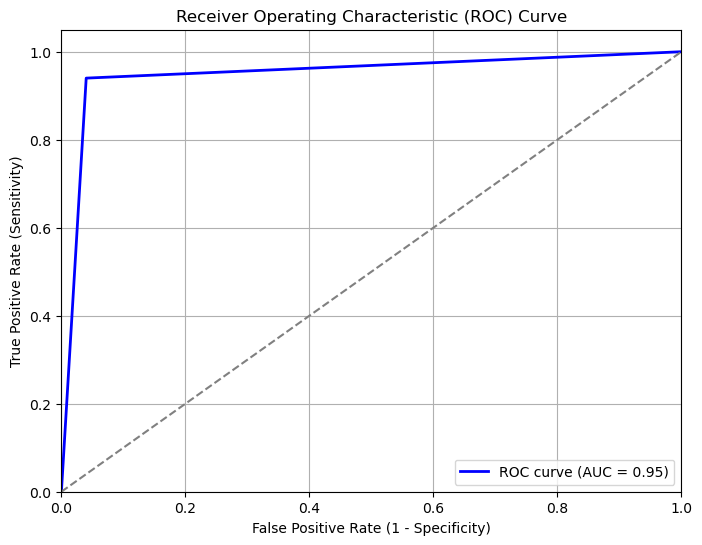

In [1]:
import numpy as np
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Given data
precision = 0.97
recall = 0.96
f1_score = 0.965
accuracy = 0.95
sensitivity = 0.94
specificity = 0.96  # Specificity = 1 - False Positive Rate (FPR)
fpr = 1 - specificity
tpr = sensitivity

# Generate ROC curve data points
fpr_values = [0, fpr, 1]
tpr_values = [0, tpr, 1]

# Compute AUC
roc_auc = auc(fpr_values, tpr_values)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr_values, tpr_values, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Diagonal line for random guessing
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid()
plt.show()

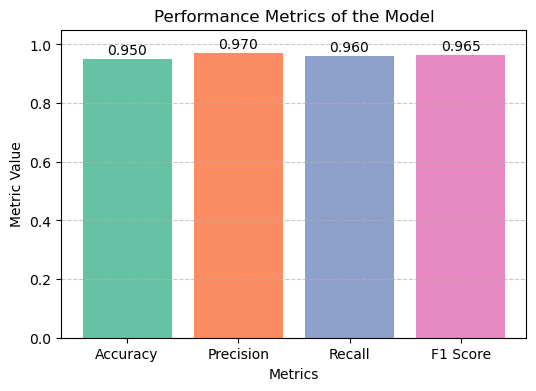

In [1]:
import matplotlib.pyplot as plt

# Performance metrics for the satellite-based flood detection model
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
values = [0.95, 0.97, 0.96, 0.965]  # Example values

# Create the figure and bar chart
plt.figure(figsize=(6, 4))
bars = plt.bar(metrics, values, color=['#66c2a5', '#fc8d62', '#8da0cb', '#e78ac3'])

# Annotate each bar with its value
for i, bar in enumerate(bars):
    plt.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 0.005,
             f"{values[i]:.3f}",
             ha='center', va='bottom', fontsize=10)

# Customize the plot
plt.ylim(0, 1.05)
plt.title('Performance Metrics of the Model')
plt.xlabel('Metrics')
plt.ylabel('Metric Value')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Display the plot
plt.show()

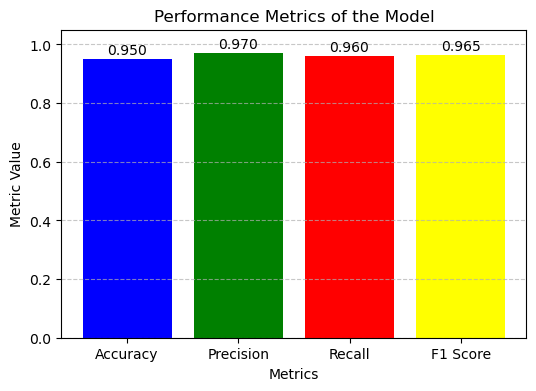

In [8]:
import matplotlib.pyplot as plt

# Performance metrics for the model
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
values = [0.95, 0.97, 0.96, 0.965]

# Create the bar chart
plt.figure(figsize=(6, 4))
bars = plt.bar(metrics, values, color=['blue', 'green', 'red', 'yellow'])

# Annotate each bar with its value
for i, bar in enumerate(bars):
    plt.text(bar.get_x() + bar.get_width() / 2, 
             bar.get_height() + 0.005, 
             f"{values[i]:.3f}", 
             ha='center', va='bottom', fontsize=10)

# Set the y-axis limit
plt.ylim(0, 1.05)

# Labeling
plt.xlabel('Metrics')
plt.ylabel('Metric Value')
plt.title('Performance Metrics of the Model')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show the plot
plt.show()